# CW 2 - AIR_A

## Import all necessary libraries

In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import random
import time
import ai4_tools as ai4

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.metrics import make_scorer

from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error
from sklearn.neighbors import KNeighborsRegressor as KNN
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

## Load data and initialise baseline pipeline

In [3]:
# Load the data
MY_FILE = "air-quality.csv"

raw = pd.read_csv(MY_FILE)

# Target and dropped columns
TARGET = "co_gt"
DROP = ["datetime", "nmhc_gt", "c6h6_gt", "nox_gt", "no2_gt", "absolute_humidity"]

df = raw.drop(columns=DROP)
df = df.replace(-200, np.nan)        # -200 means missing
df = df.dropna(subset=[TARGET])      # rows without a target can't be used
    
y = df[TARGET]
X = df.drop(columns=[TARGET])

numeric_cols = X.select_dtypes("number").columns.tolist()
text_cols = [c for c in X.columns if c not in numeric_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_cols),


# This can be removed: we do not have categorical variables
    # ("cat", Pipeline([
    #     ("impute", SimpleImputer(strategy="most_frequent")),
    #     ("onehot", OneHotEncoder(handle_unknown="ignore")) 
    # ]), text_cols)
])

pipe = Pipeline([
    ("prep", preprocess),
    ("model", LinearRegression())
])

## Initialise Cross-Validation

In [ ]:
# CROSS-VALIDATION
 
N_FOLDS = 5
METRIC = "neg_mean_absolute_error"

NO2 = raw["no2_gt"].replace(-200, np.nan)

#sensitivity
# draws a straight line through (real CO, predicted CO) and returns its slope.
# 1 = perfect
def sensitivity(y_true, y_pred):
    slope = np.polyfit(y_true, y_pred, 1)[0]
    return slope
# selectivity : how much do the predictions follow CO, compared with NO2
# higher the better, number wise
def selectivity(model, X, y):
    y_pred = model.predict(X)

    # get the real NO2 for these same rows
    no2 = NO2.loc[X.index].to_numpy()

    # ignore rows where NO2 is missing
    keep = ~np.isnan(no2)
    real_co = np.asarray(y)[keep]
    no2 = no2[keep]
    y_pred = y_pred[keep]

    # put CO, NO2 and predictions on the same scale (CO and NO2 use different units)
    def rescale(v):
        return (v - v.mean()) / v.std()

    inputs = np.column_stack([rescale(real_co), rescale(no2)])

    # how strongly do predictions follow CO, and how strongly do they follow NO2?
    follow_co, follow_no2 = LinearRegression().fit(inputs, rescale(y_pred)).coef_

    return abs(follow_co / follow_no2)
 
SCORING = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "SENS": make_scorer(sensitivity), 
    "SEL": selectivity,
}
 
# 1. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)
 
# 2. Cross-validation folds
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=0) # Remember to flag time dependence
 
# 3. Cross-validation helper
def run_cv(name, model):
    s = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=SCORING,
        return_train_score=True
    )
 
    return {
        "model": name,
        "Train MAE": -s["train_MAE"].mean(),
        "CV MAE": -s["test_MAE"].mean(),
        "CV RMSE": -s["test_RMSE"].mean(),
        "CV R²": s["test_R2"].mean(),
        "spread": s["test_MAE"].std(),
        "fit time (s)": s["fit_time"].mean()
    }
 
# 4. GridSearchCV results helper
def show_results(title, search):
    best = search.best_index_
    r = search.cv_results_
 
    print(title)
    print("  Best settings:", search.best_params_)
    print("  Training MAE:", round(-r["mean_train_score"][best], 3))
    print("  Cross-validation MAE:", round(-search.best_score_, 3))
    print("  Spread across folds:", round(r["std_test_score"][best], 3))
    print("  Training time (s):", round(r["mean_fit_time"][best], 3))
    print("  Prediction time (s):", round(r["mean_score_time"][best], 4))
    print()
 
# 5. Linear regression baseline
print(f"train {len(X_train)} rows, test {len(X_test)} rows, {N_FOLDS} folds\n")
 
print(pd.DataFrame([
    run_cv("linear regression", pipe)
]).round(3).to_string(index=False))

train 6139 rows, test 1535 rows, 5 folds

            model  Train MAE  CV MAE  CV RMSE  CV R²  spread  fit time (s)
linear regression      0.369    0.37    0.612  0.825    0.01         0.041


## kNN

Implement weighted kNN to account for outliers

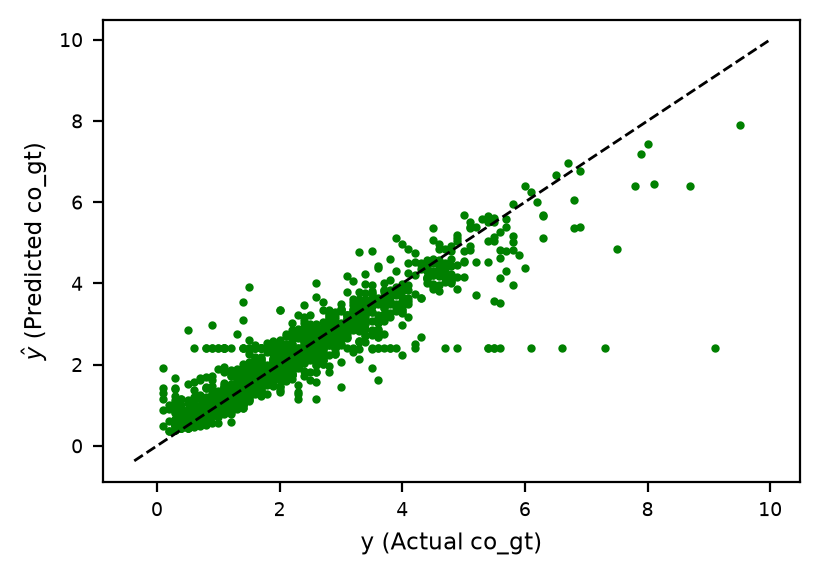

The test R^2 is: 0.84
So correct predictions occur 83.88% of the times


In [5]:
#initialise distance weighted knn
weighted_knn_model = KNN(n_neighbors=50, weights='distance')

# Build the weighted pipeline
pipeknn_weighted = Pipeline([
    ("prep", preprocess),
    ("model", weighted_knn_model)
])

pipeknn_weighted.fit(X_train, y_train)

y_test_predictions_weighted = pipeknn_weighted.predict(X_test)

plt.figure(figsize=(4.5, 3), dpi=200)
plt.plot(y_test, y_test_predictions_weighted, 'g.', markersize=4)
lim_left, lim_right = plt.xlim()
plt.plot([lim_left, lim_right], [lim_left, lim_right], '--k', linewidth=1)
plt.xlabel("y (Actual co_gt)", fontsize='small')
plt.ylabel(r"$\hat{y}$ (Predicted co_gt)", fontsize='small')
plt.tick_params(axis='both', labelsize=7)
plt.show()

r2 = pipeknn_weighted.score(X_test, y_test)
print('The test R^2 is: {:.2f}'.format(r2))
print("So correct predictions occur {:.2f}% of the times".format(r2 * 100))

Improved performance -> reason to believe implementing weighting leads to an improved model.

### Tune on weighted kNN

In [6]:
pipe_knn_full = Pipeline([
    ('prep', preprocess),
    ('model', KNN())
])

# Configure the search space for neighbors
neighbor = list(range(1, 100, 2))
param_grid = {
    'model__n_neighbors': neighbor,
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan', 'minkowski'],
    'model__leaf_size': [20, 30, 40, 50]
}

# Perform Grid Search using the previously defined cross-validation splitter (cv)
# and the complete SCORING dictionary defined earlier. We must set refit='MAE' 
# to indicate which metric determines the best estimator.
print("Optimizing kNN parameters using established cross-validation and custom scoring...")
knn_grid_search = GridSearchCV(
    pipe_knn_full,
    param_grid,
    cv=cv,
    scoring=SCORING,
    refit='MAE',
    n_jobs=-1,
    return_train_score=True
)
knn_grid_search.fit(X_train, y_train)

best_knn_params = knn_grid_search.best_params_
print(f"\nBest kNN parameters: {best_knn_params}")
print(f"Best CV negative MAE: {knn_grid_search.best_score_:.4f}")

# Evaluate the final optimized model on the test dataset
optimized_knn_full_r2 = knn_grid_search.best_estimator_.score(X_test, y_test)
print(f"Optimized kNN Test R-squared: {optimized_knn_full_r2:.4f}")

Optimizing kNN parameters using established cross-validation and custom scoring...

Best kNN parameters: {'model__leaf_size': 40, 'model__metric': 'manhattan', 'model__n_neighbors': 11, 'model__weights': 'distance'}
Best CV negative MAE: -0.3264
Optimized kNN Test R-squared: 0.8474


In [7]:
# Extract cross-validation results from the grid search
results_dict = knn_grid_search.cv_results_

# Create a DataFrame to hold the configurations and their scores
performance_data = []
for i in range(len(results_dict['params'])):
    row = {
        "n_neighbors": results_dict['param_model__n_neighbors'][i],
        "weights": results_dict['param_model__weights'][i],
        "metric": results_dict['param_model__metric'][i],
        "leaf_size": results_dict['param_model__leaf_size'][i],
        # Convert negative MAE and RMSE to positive values for standard presentation
        "MAE (Validation)": -results_dict['mean_test_MAE'][i],
        "RMSE (Validation)": -results_dict['mean_test_RMSE'][i],
        "R² (Validation)": results_dict['mean_test_R2'][i],
        "Sensitivity (Validation)": results_dict['mean_test_SENS'][i],
        "Selectivity (Validation)": results_dict['mean_test_SEL'][i],
        "Fit Time (s)": results_dict['mean_fit_time'][i],
        "Prediction Time (s)": results_dict['mean_score_time'][i]
    }
    performance_data.append(row)

rank_df = pd.DataFrame(performance_data)

# Rank models primarily by Mean Absolute Error (MAE)
rank_df = rank_df.sort_values(by="MAE (Validation)", ascending=True).reset_index(drop=True)
rank_df.index += 1
rank_df.index.name = 'Rank'

print("=== Top 10 Best Performing kNN Models ===")
display(rank_df.head(10).round(3))

=== Top 10 Best Performing kNN Models ===


,n_neighbors,weights,metric,leaf_size,MAE (Validation),RMSE (Validation),R² (Validation),Sensitivity (Validation),Selectivity (Validation),Fit Time (s),Prediction Time (s)
Rank,,,,,,,,,,,
1,11,distance,manhattan,50,0.326,0.560,0.853,0.833,23.434,0.039,0.196
2,11,distance,manhattan,40,0.326,0.560,0.853,0.833,23.434,0.044,0.197
3,9,distance,manhattan,40,0.326,0.563,0.851,0.837,24.204,0.082,0.403
4,9,distance,manhattan,50,0.326,0.563,0.851,0.837,24.204,0.050,0.253
5,9,distance,euclidean,40,0.327,0.566,0.850,0.837,24.869,0.050,0.154
6,9,distance,euclidean,50,0.327,0.566,0.850,0.837,24.869,0.047,0.138
7,9,distance,minkowski,40,0.327,0.566,0.850,0.837,24.869,0.104,0.230
8,9,distance,minkowski,50,0.327,0.566,0.850,0.837,24.869,0.047,0.125
9,11,distance,euclidean,50,0.327,0.563,0.852,0.833,22.787,0.057,0.134


Selected best model based on compromise

In [8]:
optimized_knn = KNN(
    n_neighbors=9,
    weights='distance',
    metric='euclidean',
    leaf_size=50
)


optimized_pipe_knn = Pipeline([
    ("prep", preprocess),
    ("model", optimized_knn)
])

# Benchmark the optimized pipeline directly using ai4_tools
optimized_results_knn = ai4.benchmark(
    optimized_pipe_knn,
    X_train,
    y_train,
    X_test,
    y_test,
    label="Optimized Distance-Weighted kNN (k=9)"
)

# Create and display the results table
table = ai4.ResultsTable()
table.add("Optimized Distance-Weighted kNN (k=9)", optimized_results_knn)
display(table.df().round(3))

,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats
0,Optimized Distance-Weighted kNN (k=9),0.852,0.035,51.739,0.034,0.079,6139,1535,3


### Define ranker for future use

In [9]:
def ranker(grid_search, sort_by_metric="mean_test_MAE", ascending=True):
    results = grid_search.cv_results_
    df_data = {}
    
    # 1. Automatically extract all hyperparameter columns
    for key in results.keys():
        if key.startswith("param_"):
            # Clean up the key name (e.g., 'param_model__n_neighbors' -> 'n_neighbors')
            clean_name = key.replace("param_model__", "").replace("param_", "")
            df_data[clean_name] = results[key]
            
    # 2. Automatically extract all evaluation metric columns
    for key in results.keys():
        if key.startswith("mean_test_") or key.startswith("mean_fit_time") or key.startswith("mean_score_time"):
            clean_name = key.replace("mean_test_", "")
            # Convert negative metrics to positive for standard display
            if "neg_" in clean_name:
                display_name = clean_name.replace("neg_", "") + " (Val)"
                df_data[display_name] = -results[key]
            else:
                display_name = clean_name + " (Val)" if "time" not in clean_name else clean_name
                df_data[display_name] = results[key]
                
    # Convert to DataFrame and Rank
    rank_df = pd.DataFrame(df_data)
    
    # Determine the column name to sort by
    sort_col = sort_by_metric.replace("mean_test_", "").replace("neg_", "") + " (Val)"
    if sort_col in rank_df.columns:
        rank_df = rank_df.sort_values(by=sort_col, ascending=ascending).reset_index(drop=True)
        
    rank_df.index += 1
    rank_df.index.name = 'Rank'
    
    print(f"=== Top 10 Best Performing Models (Sorted by {sort_col}) ===")
    display(rank_df.head(10).round(3))

Testing for curse of dimensionality in kNN

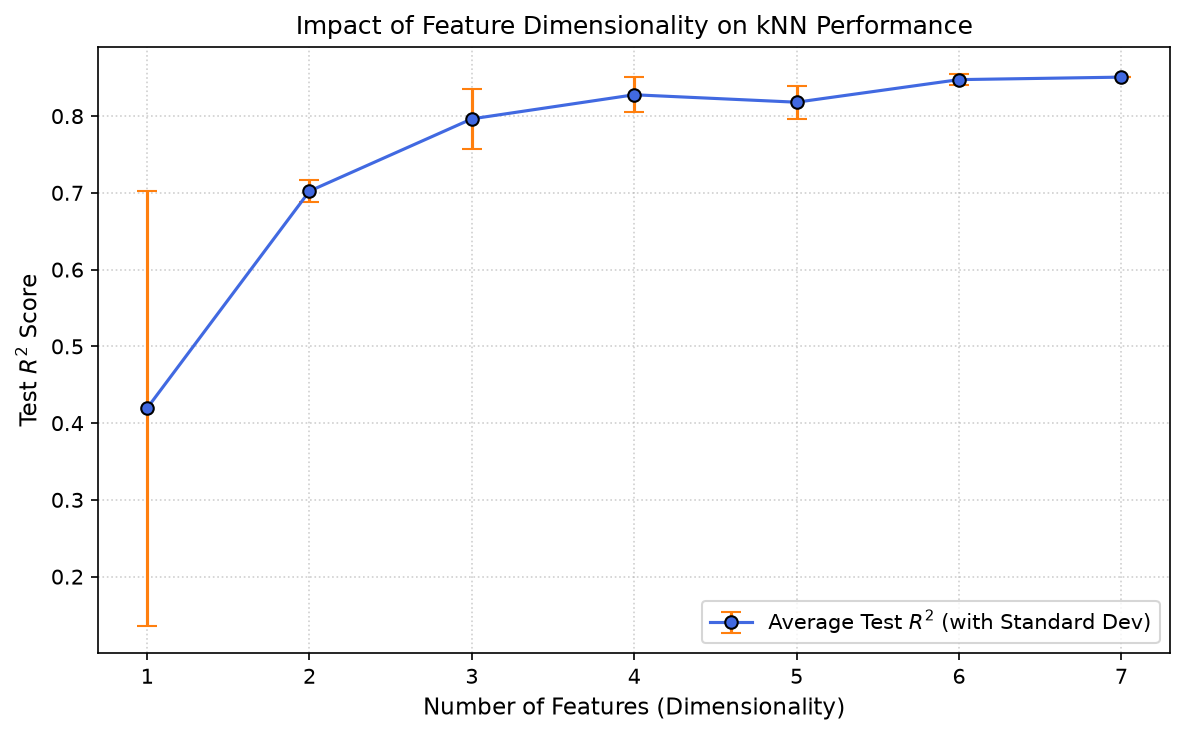

In [13]:
all_features = X_train.columns.tolist()
dimensions = list(range(1, len(all_features) + 1))

# Run the experiment multiple times to get an average behavior
num_trials = 5
dim_scores = {d: [] for d in dimensions}

# Re-use the optimized kNN parameters found during grid search
knn_experiment_model = KNN(
    n_neighbors=9,
    weights='distance',
    metric='euclidean',
    leaf_size=50
)

experiment_pipeline = Pipeline([
    ('prep', Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ])),
    ('model', knn_experiment_model)
])

for d in dimensions:
    for trial in range(num_trials):
        # Randomly select 'd' features
        random.seed(trial * d + 42) # Ensure reproducible randomness
        selected_features = random.sample(all_features, d)

        # Subset the data
        X_tr_sub = X_train[selected_features]
        X_te_sub = X_test[selected_features]

        # Train and score
        experiment_pipeline.fit(X_tr_sub, y_train)
        score = experiment_pipeline.score(X_te_sub, y_test)
        dim_scores[d].append(score)

# Compute average and standard deviation of scores for each dimension
avg_scores = [np.mean(dim_scores[d]) for d in dimensions]
std_scores = [np.std(dim_scores[d]) for d in dimensions]

# Plot the results
plt.figure(figsize=(8, 5), dpi=150)
plt.errorbar(dimensions, avg_scores, yerr=std_scores, fmt='-o', color='royalblue', ecolor='tab:orange', capsize=5, elinewidth=1.5, markeredgecolor='black', label='Average Test $R^2$ (with Standard Dev)')
plt.title('Impact of Feature Dimensionality on kNN Performance')
plt.xlabel('Number of Features (Dimensionality)', fontsize=11)
plt.ylabel('Test $R^2$ Score', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(dimensions)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

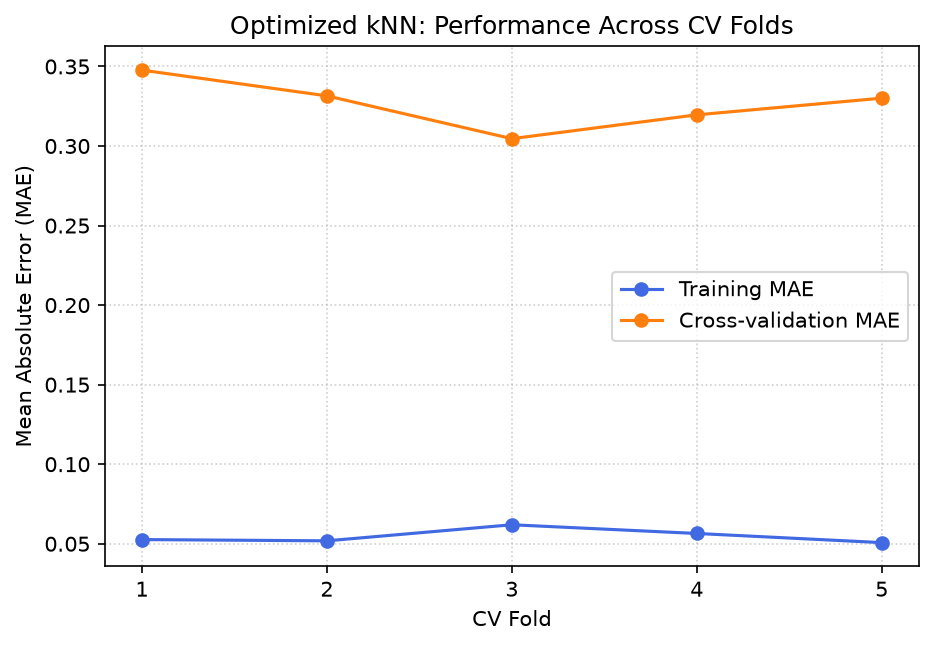

In [ ]:
cv_results_knn = cross_validate(
    optimized_pipe_knn, X_train, y_train,
    cv=cv,
    scoring=SCORING,
    return_train_score=True
)

# Extract training and cross-validation MAE
train_mae = -cv_results_knn["train_MAE"]
cv_mae = -cv_results_knn["test_MAE"]
folds = range(1, len(train_mae) + 1)

# Plot the curves following the established design guidelines
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)

ax.plot(
    folds,
    train_mae,
    "o-", color="royalblue", label="Training MAE"
)
ax.plot(
    folds,
    cv_mae,
    "o-", color="tab:orange", label="Cross-validation MAE"
)

ax.set_xlabel("CV Fold")
ax.set_ylabel("Mean Absolute Error (MAE)")
ax.set_title("Optimized kNN: Performance Across CV Folds")
ax.set_xticks(folds)
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
plt.show()

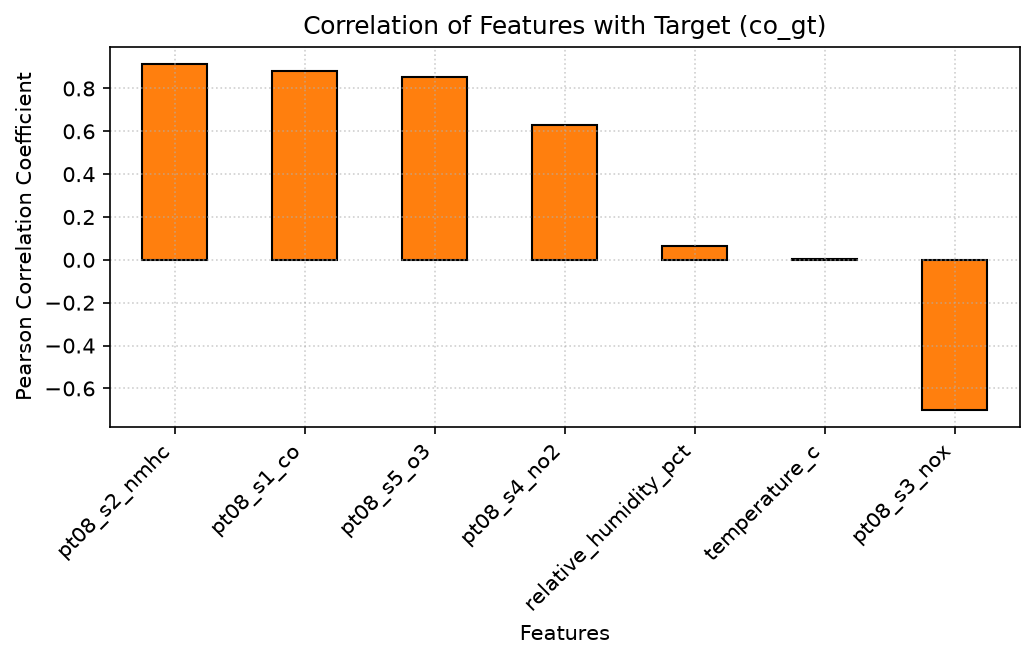

In [ ]:
# Calculate correlation of each feature in X_train with the target y_train
correlations_knn = X_train.corrwith(y_train).sort_values(ascending=False)

# Plot the correlation with each feature using a bar chart
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)

correlations_knn.plot(kind="bar", color="tab:orange", ax=ax, edgecolor="black")

ax.set_title("Correlation of Features with Target (co_gt)", fontsize=12)
ax.set_xlabel("Features", fontsize=10)
ax.set_ylabel("Pearson Correlation Coefficient", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## SVR

In [14]:
pipe_svm_full = Pipeline([
    ("prep", preprocess),
    ('model', SVR())
])

cs = np.logspace(-3, 3, 13)
epsilons = np.logspace(-3, 0, 7)

svm_param_grid_full = {
    'model__C': cs,
    'model__epsilon': epsilons,
    'model__gamma': ['scale', 'auto', 0.01, 0.1]
}

# 3. Perform Grid Search with 5-fold Cross-Validation on full dataset
print("Optimizing SVR parameters on the full dataset...")
svm_grid_search_full = GridSearchCV(
    pipe_svm_full,
    svm_param_grid_full,
    cv=cv,
    scoring=SCORING,
    refit='MAE',
    n_jobs=-1,
    return_train_score=True
)
svm_grid_search_full.fit(X_train, y_train)

best_svm_full_params = svm_grid_search_full.best_params_
print(f"Best SVM parameters: {best_svm_full_params}")
print(f"Best negative MAE: {svm_grid_search_full.best_score_:.4f}")

# 5. Score best estimator on full test data
optimized_svm_full_r2 = svm_grid_search_full.best_estimator_.score(X_test, y_test)
y_pred_svm_full = svm_grid_search_full.best_estimator_.predict(X_test)
svm_full_mae = mean_absolute_error(y_test, y_pred_svm_full)

print(f"Optimized SVR (Full Features) Test R-squared: {optimized_svm_full_r2:.4f}")
print(f"Optimized SVR (Full Features) Test MAE:       {svm_full_mae:.4f}")

Optimizing SVR parameters on the full dataset...
Best SVM parameters: {'model__C': np.float64(100.0), 'model__epsilon': np.float64(0.1), 'model__gamma': 'scale'}
Best negative MAE: -0.2965
Optimized SVR (Full Features) Test R-squared: 0.8536
Optimized SVR (Full Features) Test MAE:       0.2844


In [20]:
ranker(svm_grid_search_full, sort_by_metric="mean_test_MAE", ascending=False)

=== Top 10 Best Performing Models (Sorted by MAE (Val)) ===


,C,epsilon,gamma,mean_fit_time,mean_score_time,MAE (Val),RMSE (Val),R2 (Val),SENS (Val),SEL (Val)
Rank,,,,,,,,,,
1,100.000,0.100,scale,24.978,1.607,-0.297,-0.542,0.862,0.868,32.623
2,100.000,0.100,auto,26.695,1.578,-0.297,-0.542,0.862,0.868,32.623
3,31.623,0.100,auto,7.735,1.257,-0.297,-0.544,0.861,0.864,31.401
4,31.623,0.100,scale,8.215,1.690,-0.297,-0.544,0.861,0.864,31.401
5,316.228,0.100,0.1,68.373,1.626,-0.297,-0.544,0.861,0.868,32.799
6,100.000,0.032,scale,29.100,2.106,-0.297,-0.544,0.861,0.867,31.911
7,100.000,0.032,auto,34.264,2.152,-0.297,-0.544,0.861,0.867,31.911
8,31.623,0.032,scale,9.291,1.624,-0.298,-0.545,0.861,0.862,34.150
9,31.623,0.032,auto,9.180,1.568,-0.298,-0.545,0.861,0.862,34.150


In [21]:
optimised_svr = SVR(
    C=31.623,  # This is approximately 10^(1.5)
    epsilon=0.032,  # This is approximately 10^(-1.5)
    gamma='scale'
)

optimised_pipe_svr = Pipeline([
    ("prep", preprocess),
    ("model", optimised_svr)
])

optimised_results_svr = ai4.benchmark(
    optimised_pipe_svr,
    X_train,
    y_train,
    X_test,
    y_test,
    label="Optimised SVR (C=100, epsilon=0.1, gamma='scale')"
)

# Create and display the results table
table = ai4.ResultsTable()
table.add("Optimised SVR (C=100, epsilon=0.1, gamma='scale')", optimised_results_svr)
display(table.df().round(3))

,model,score,fit_s,predict_ms_per_1k,fit_s_best,predict_s,n_train,n_test,repeats
0,"Optimised SVR (C=100, epsilon=0.1, gamma='scale')",0.852,11.467,693.903,11.448,1.065,6139,1535,3


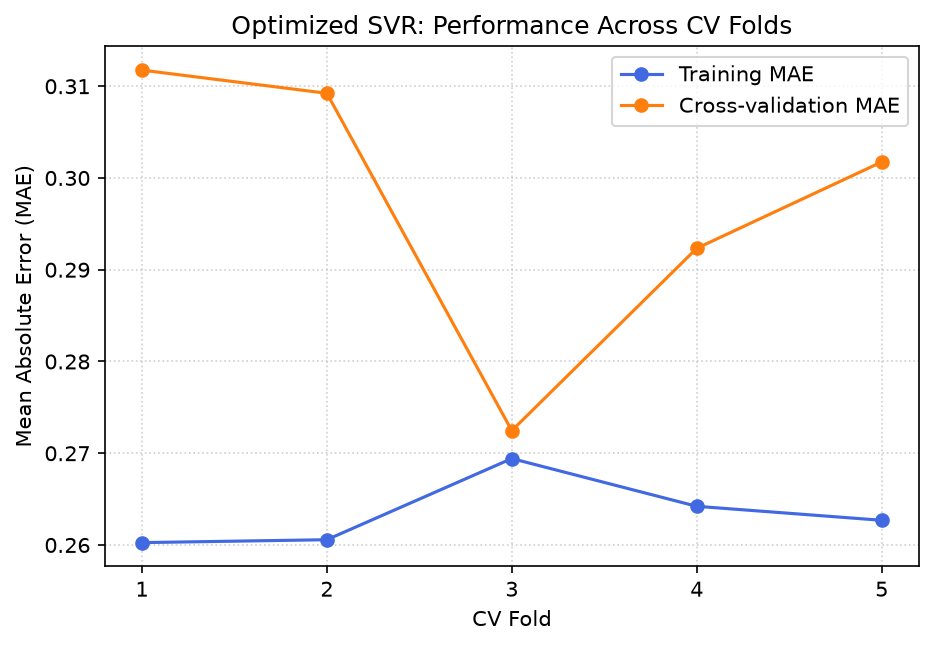

In [22]:
cv_results_svr = cross_validate(
    optimised_pipe_svr, X_train, y_train,
    cv=cv,
    scoring=SCORING,
    return_train_score=True
)

# Extract training and cross-validation MAE
train_mae = -cv_results_svr["train_MAE"]
cv_mae = -cv_results_svr["test_MAE"]
folds = range(1, len(train_mae) + 1)

# Plot the curves following the established design guidelines
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)

ax.plot(
    folds,
    train_mae,
    "o-", color="royalblue", label="Training MAE"
)
ax.plot(
    folds,
    cv_mae,
    "o-", color="tab:orange", label="Cross-validation MAE"
)

ax.set_xlabel("CV Fold")
ax.set_ylabel("Mean Absolute Error (MAE)")
ax.set_title("Optimized SVR: Performance Across CV Folds")
ax.set_xticks(folds)
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
plt.show()

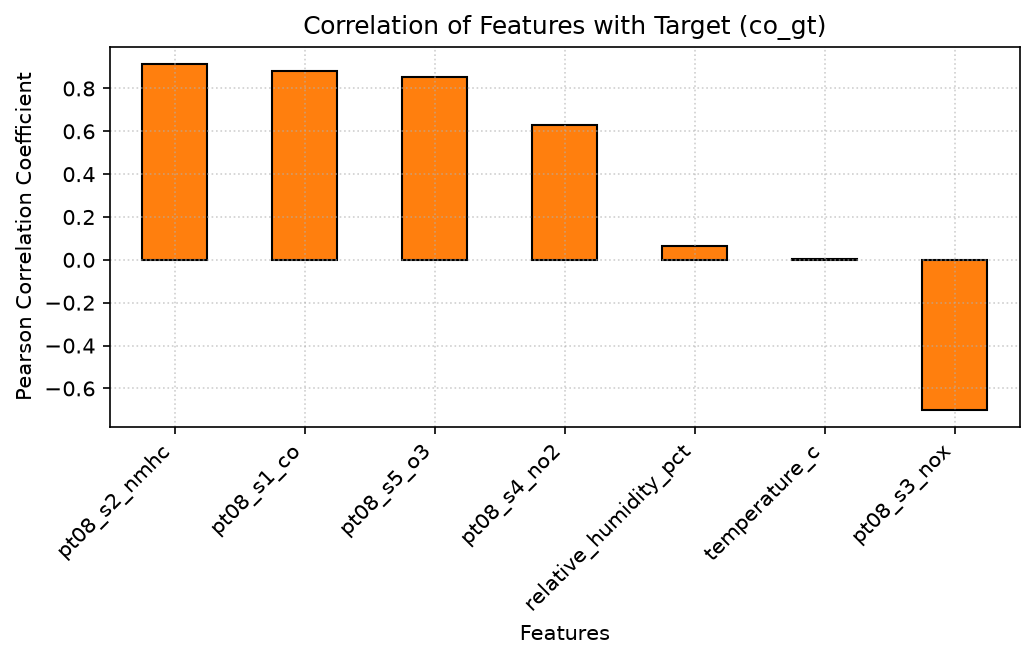

In [23]:
# Calculate correlation of each feature in X_train with the target y_train
correlations_svr = X_train.corrwith(y_train).sort_values(ascending=False)

# Plot the correlation with each feature using a bar chart
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)

correlations_svr.plot(kind="bar", color="tab:orange", ax=ax, edgecolor="black")

ax.set_title("Correlation of Features with Target (co_gt)", fontsize=12)
ax.set_xlabel("Features", fontsize=10)
ax.set_ylabel("Pearson Correlation Coefficient", fontsize=10)
ax.grid(True, linestyle=":", alpha=0.6)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Gradient Boosting

In [18]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class CorrelationSelector(TransformerMixin, BaseEstimator):
    """Keep features with enough absolute correlation to the training target."""

    def __init__(self, threshold=0.10):
        self.threshold = threshold

    def fit(self, X, y):
        target = pd.Series(np.asarray(y), index=X.index)
        correlations = X.corrwith(target).abs().fillna(0.0)
        self.selected_features_ = correlations.index[
            correlations >= self.threshold
        ].tolist()

        if not self.selected_features_:
            raise ValueError("No features passed the correlation threshold.")
        return self

    def transform(self, X):
        check_is_fitted(self, "selected_features_")
        return X.loc[:, self.selected_features_]


gb_pipe = Pipeline([
    ("select", CorrelationSelector(threshold=0.10)),
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("model", GradientBoostingRegressor(random_state=0)),
])

gb_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [5, 10],
}

search_gb = GridSearchCV(
    gb_pipe,
    gb_grid,
    cv=cv,
    scoring=SCORING,
    refit="MAE",
    return_train_score=True,
    n_jobs=2,
    error_score="raise",
)
search_gb.fit(X_train, y_train)
gb_model = search_gb.best_estimator_

gb_best = pd.DataFrame(search_gb.cv_results_).iloc[search_gb.best_index_]

print("Best settings:", search_gb.best_params_)
print("Selected features:", gb_model.named_steps["select"].selected_features_)

pd.DataFrame([{
    "Model": "Gradient Boosting v2",
    "Training MAE": -gb_best["mean_train_MAE"],
    "CV MAE": -gb_best["mean_test_MAE"],
    "CV RMSE": -gb_best["mean_test_RMSE"],
    "CV R²": gb_best["mean_test_R2"],
    "CV sensitivity": gb_best["mean_test_SENS"],
    "CV selectivity": gb_best["mean_test_SEL"],
}]).round(4)

Best settings: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__n_estimators': 300}
Selected features: ['pt08_s1_co', 'pt08_s2_nmhc', 'pt08_s3_nox', 'pt08_s4_no2', 'pt08_s5_o3']


,Model,Training MAE,CV MAE,CV RMSE,CV R²,CV sensitivity,CV selectivity
0,Gradient Boosting v2,0.3052,0.3349,0.5674,0.8493,0.8484,23.0526


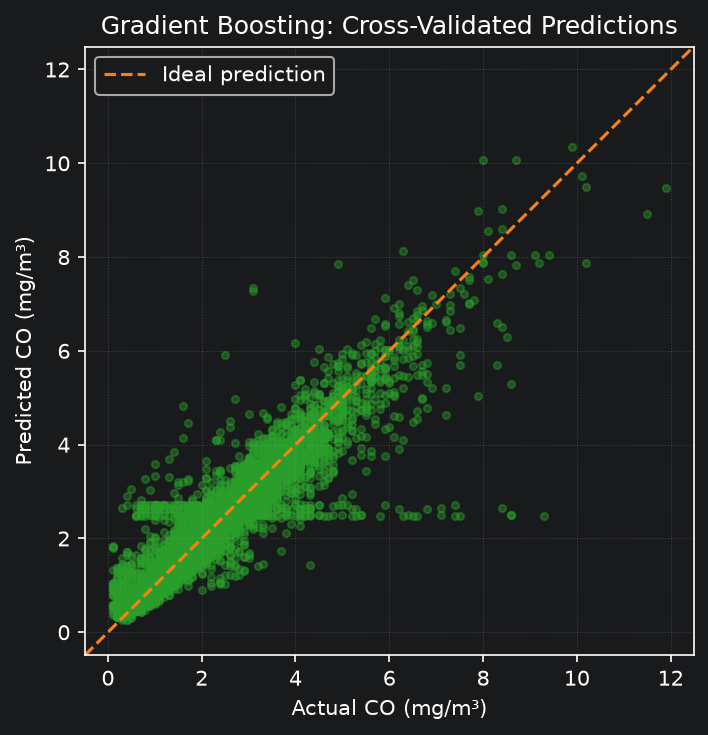

In [29]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Predictions from the selected configuration across the shared CV folds
gb_oof_predictions = cross_val_predict(
    clone(search_gb.best_estimator_),
    X_train,
    y_train,
    cv=search_gb.cv,
    n_jobs=2
)

fig, ax = plt.subplots(figsize=(6, 5), dpi=150)

ax.scatter(
    y_train, gb_oof_predictions,
    color="tab:green", s=12, alpha=0.4
)

# Ideal predictions: actual = predicted
gb_low = min(y_train.min(), gb_oof_predictions.min())
gb_high = max(y_train.max(), gb_oof_predictions.max())
gb_margin = 0.05 * (gb_high - gb_low)
gb_limits = [gb_low - gb_margin, gb_high + gb_margin]

ax.plot(
    gb_limits, gb_limits,
    "--", color="tab:orange", linewidth=1.5,
    label="Ideal prediction"
)

ax.set(
    title="Gradient Boosting: Cross-Validated Predictions",
    xlabel="Actual CO (mg/m³)",
    ylabel="Predicted CO (mg/m³)",
    xlim=gb_limits,
    ylim=gb_limits
)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, linestyle=":", alpha=0.25)
ax.legend()

fig.tight_layout()
plt.show()

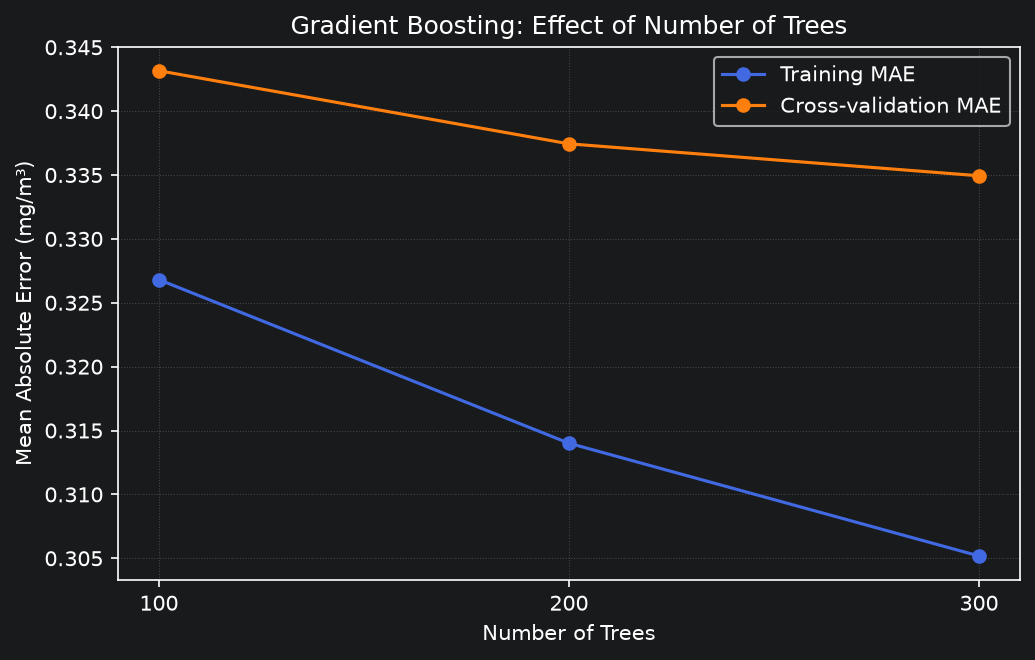

Other parameters held fixed: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 10}


In [30]:
gb_search_results = pd.DataFrame(search_gb.cv_results_)

# Hold all searched parameters except tree count fixed
gb_fixed_params = {
    name: value
    for name, value in search_gb.best_params_.items()
    if name != "model__n_estimators"
}

gb_matching_rows = gb_search_results["params"].apply(
    lambda params: all(
        params[name] == value
        for name, value in gb_fixed_params.items()
    )
)

gb_tree_curve = gb_search_results.loc[gb_matching_rows].copy()

gb_tree_curve["Number of trees"] = (
    gb_tree_curve["param_model__n_estimators"].astype(int)
)
gb_tree_curve["Training MAE"] = -gb_tree_curve["mean_train_MAE"]
gb_tree_curve["CV MAE"] = -gb_tree_curve["mean_test_MAE"]

gb_tree_curve = gb_tree_curve.sort_values("Number of trees")

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=150)

ax.plot(
    gb_tree_curve["Number of trees"],
    gb_tree_curve["Training MAE"],
    "o-", color="royalblue", label="Training MAE"
)
ax.plot(
    gb_tree_curve["Number of trees"],
    gb_tree_curve["CV MAE"],
    "o-", color="tab:orange", label="Cross-validation MAE"
)

ax.set(
    title="Gradient Boosting: Effect of Number of Trees",
    xlabel="Number of Trees",
    ylabel="Mean Absolute Error (mg/m³)",
    xticks=gb_tree_curve["Number of trees"].tolist()
)
ax.grid(True, linestyle=":", alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

print("Other parameters held fixed:", gb_fixed_params)

In [31]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.ensemble import GradientBoostingRegressor

# Same preprocessing, with default boosting parameters
gb_default_pipe = clone(search_gb.estimator).set_params(
    model=GradientBoostingRegressor(random_state=0)
)

gb_default_cv = cross_validate(
    gb_default_pipe,
    X_train,
    y_train,
    cv=search_gb.cv,
    scoring={
        "MAE": SCORING["MAE"],
        "R2": SCORING["R2"]
    },
    return_train_score=True,
    n_jobs=2,
    error_score="raise"
)

gb_selected_result = pd.DataFrame(
    search_gb.cv_results_
).iloc[search_gb.best_index_]

gb_comparison = pd.DataFrame([
    {
        "Model": "Default boosting",
        "Training MAE": -gb_default_cv["train_MAE"].mean(),
        "CV MAE": -gb_default_cv["test_MAE"].mean(),
        "CV MAE SD": gb_default_cv["test_MAE"].std(ddof=0),
        "CV R²": gb_default_cv["test_R2"].mean()
    },
    {
        "Model": "Tuned boosting",
        "Training MAE": -gb_selected_result["mean_train_MAE"],
        "CV MAE": -gb_selected_result["mean_test_MAE"],
        "CV MAE SD": gb_selected_result["std_test_MAE"],
        "CV R²": gb_selected_result["mean_test_R2"]
    }
])

gb_comparison["MAE gap"] = (
    gb_comparison["CV MAE"] - gb_comparison["Training MAE"]
)

print("MAE values and standard deviations are in mg/m³.")
display(gb_comparison.round(4))

gb_default_mae = gb_comparison.loc[0, "CV MAE"]
gb_tuned_mae = gb_comparison.loc[1, "CV MAE"]
gb_improvement = 100 * (gb_default_mae - gb_tuned_mae) / gb_default_mae

print(f"CV MAE reduction from tuning: {gb_improvement:.2f}%")

MAE values and standard deviations are in mg/m³.


,Model,Training MAE,CV MAE,CV MAE SD,CV R²,MAE gap
0,Default boosting,0.3103,0.3366,0.0126,0.8489,0.0263
1,Tuned boosting,0.3052,0.3349,0.0123,0.8493,0.0298


CV MAE reduction from tuning: 0.49%


## Random forest regression

### Decision Tree Regressor

Benjamin's code

decision tree tests different feature values to split data into groups and make predictions based on learned patterns

Most precise depth was tested to be 12 with the ideal sample leafs taken as 24 Was tested through taking a range of values, however repeating this takes ages to load the code

In [19]:
from sklearn.ensemble import RandomForestRegressor


# Random Forest pipeline

rf_pipe = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestRegressor(random_state=0))
])


# STEP 1: Wide search to identify the best hyperparameter region

wide_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, 20, None],
    "model__min_samples_leaf": [5, 10, 20],
    "model__max_features": [0.5, 1.0]
}

wide_search_rf = GridSearchCV(
    rf_pipe,
    wide_grid,
    cv=cv,
    scoring=METRIC,
    return_train_score=True,
    n_jobs=-1
)

wide_search_rf.fit(X_train, y_train)

show_results("WIDE SEARCH", wide_search_rf)


# STEP 2: Narrow search around the best hyperparameter region

narrow_grid = {
    "model__n_estimators": [150, 200, 250],
    "model__max_depth": [15, 20, 25, None],
    "model__min_samples_leaf": [5, 7, 10, 15],
    "model__max_features": [0.4, 0.5, 0.6]
}

search_rf = GridSearchCV(
    rf_pipe,
    narrow_grid,
    cv=cv,
    scoring=METRIC,
    return_train_score=True,
    n_jobs=-1
)

search_rf.fit(X_train, y_train)

show_results("NARROW SEARCH (final)", search_rf)

WIDE SEARCH
  Best settings: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
  Training MAE: 0.239
  Cross-validation MAE: 0.317
  Spread across folds: 0.013
  Training time (s): 1.274
  Prediction time (s): 0.0381

NARROW SEARCH (final)
  Best settings: {'model__max_depth': 25, 'model__max_features': 0.6, 'model__min_samples_leaf': 5, 'model__n_estimators': 250}
  Training MAE: 0.234
  Cross-validation MAE: 0.316
  Spread across folds: 0.012
  Training time (s): 2.061
  Prediction time (s): 0.0529



In [21]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Best trained models
linear_model = pipe.fit(X_train, y_train)
tree_model = search.best_estimator_
forest_model = search_rf.best_estimator_

# Predictions on the same test set
linear_pred = linear_model.predict(X_test)
tree_pred = tree_model.predict(X_test)
forest_pred = forest_model.predict(X_test)

models = {
    "Linear Regression": linear_pred,
    "Decision Tree": tree_pred,
    "Random Forest": forest_pred
}

NameError: name 'search' is not defined

NameError: name 'models' is not defined

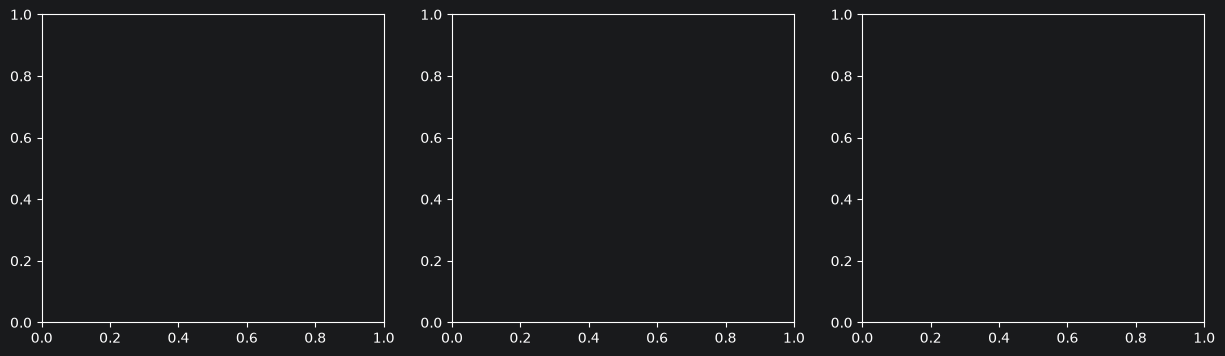

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(axes, models.items()):

    ax.scatter(y_test, predictions, alpha=0.4)

    # Perfect prediction line
    minimum = min(y_test.min(), predictions.min())
    maximum = max(y_test.max(), predictions.max())

    ax.plot(
        [minimum, maximum],
        [minimum, maximum],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual CO concentration")
    ax.set_ylabel("Predicted CO concentration")

plt.tight_layout()
plt.show()

In [23]:
names = []
mae_scores = []
rmse_scores = []
r2_scores = []

for name, predictions in models.items():

    names.append(name)

    mae_scores.append(
        mean_absolute_error(y_test, predictions)
    )

    rmse_scores.append(
        np.sqrt(mean_squared_error(y_test, predictions))
    )

    r2_scores.append(
        r2_score(y_test, predictions)
    )


NameError: name 'models' is not defined

NameError: name 'models' is not defined

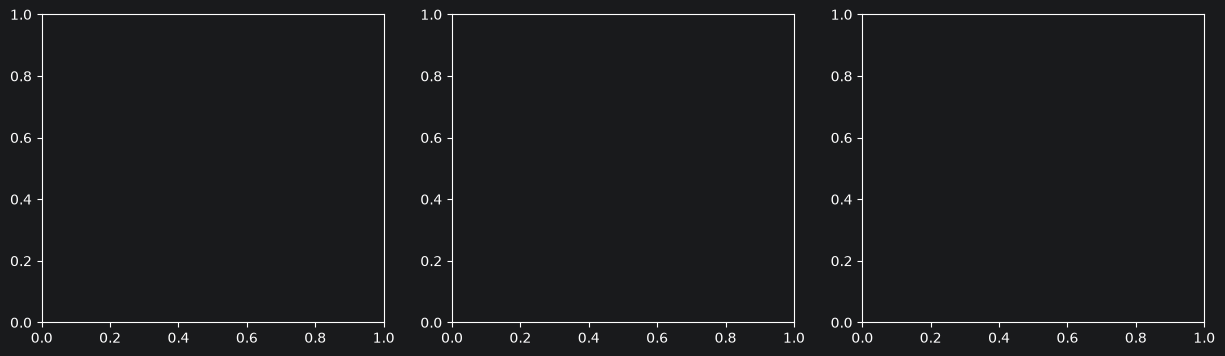

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(axes, models.items()):

    residuals = y_test - predictions

    ax.scatter(predictions, residuals, alpha=0.4)

    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(name)
    ax.set_xlabel("Predicted CO concentration")
    ax.set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

In [25]:
# Get results from the Decision Tree grid search
results = pd.DataFrame(search.cv_results_)

# Keep the best min_samples_leaf setting fixed
best_leaf = search.best_params_["model__min_samples_leaf"]

filtered = results[
    results["param_model__min_samples_leaf"] == best_leaf
].sort_values("param_model__max_depth")

depth = filtered["param_model__max_depth"]

train_mae = -filtered["mean_train_score"]
cv_mae = -filtered["mean_test_score"]

plt.figure(figsize=(8, 5))

plt.plot(depth, train_mae, "o-", label="Training MAE")
plt.plot(depth, cv_mae, "o-", label="Cross-validation MAE")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean Absolute Error")
plt.title("Decision Tree: Effect of Maximum Depth")

plt.legend()
plt.grid(True)
plt.show()

NameError: name 'search' is not defined

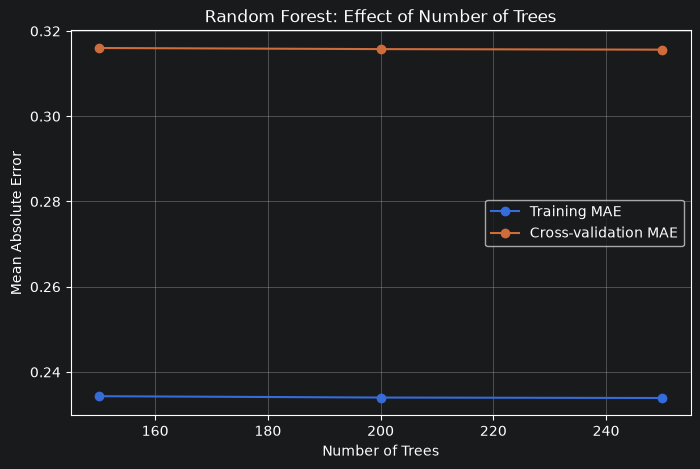

In [26]:
# Get Random Forest grid search results
results_rf = pd.DataFrame(search_rf.cv_results_)

# Keep other hyperparameters fixed
best_depth = search_rf.best_params_["model__max_depth"]
best_leaf = search_rf.best_params_["model__min_samples_leaf"]
best_features = search_rf.best_params_["model__max_features"]

filtered_rf = results_rf[
    (results_rf["param_model__max_depth"] == best_depth) &
    (results_rf["param_model__min_samples_leaf"] == best_leaf) &
    (results_rf["param_model__max_features"] == best_features)
].sort_values("param_model__n_estimators")

n_trees = filtered_rf["param_model__n_estimators"]

train_mae_rf = -filtered_rf["mean_train_score"]
cv_mae_rf = -filtered_rf["mean_test_score"]

plt.figure(figsize=(8, 5))

plt.plot(n_trees, train_mae_rf, "o-", label="Training MAE")
plt.plot(n_trees, cv_mae_rf, "o-", label="Cross-validation MAE")

plt.xlabel("Number of Trees")
plt.ylabel("Mean Absolute Error")
plt.title("Random Forest: Effect of Number of Trees")

plt.legend()
plt.grid(True)
plt.show()

### Random Forest Feature Importance

Bar chart showing the relative importance of the input features used by the Random Forest model to predict CO concentration. Longer bars indicates greater feature importance.

In [27]:
# Get feature names after preprocessing
feature_names = forest_model.named_steps["prep"].get_feature_names_out()

# Get Random Forest feature importances
importances = forest_model.named_steps["model"].feature_importances_

# Create and sort the results
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

# Plot the 10 most important features
top_features = importance_df.head(10)

plt.figure(figsize=(9, 5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.title("Random Forest: Top 10 Features")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

NameError: name 'forest_model' is not defined

## Cost analysis

In [28]:
# Load the data, parse dates, and sort in true chronological order.
df = pd.read_csv(r"C:\Users\44747\Desktop\3. AI\Data\air-quality.csv")
df["datetime"] = pd.to_datetime(df["datetime"], format="%Y-%m-%d %H:%M:%S")
df = df.sort_values("datetime").replace(-200, float("nan"))

# Keep rows with a known CO value for this model comparison.
known_co = df.dropna(subset=["co_gt"])

# Use the other measurements to predict CO.
X = known_co.drop(columns=["datetime", "co_gt"])
y = known_co["co_gt"]

# Train on the earlier 80% and test on the later 20%.
split = int(len(known_co) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Each pipeline imputes missing inputs; kNN also scales features.
models = {
    "Decision tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeRegressor(random_state=0),
    ),
    "Random forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=25, max_depth=8, random_state=0, n_jobs=1
        ),
    ),
    "kNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5),
    ),
    "Gradient boosting": make_pipeline(
        SimpleImputer(strategy="median"),
        GradientBoostingRegressor(random_state=0),
    ),
}

results = []

for name, model in models.items():
    fit_times_ms = []

    # Repeat fitting to reduce the effect of one unusually fast or slow run.
    for _ in range(3):
        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_times_ms.append((time.perf_counter() - start) * 1000)

    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    median_fit_ms = sorted(fit_times_ms)[1]

    results.append({
        "Model": name,
        "Test MAE": mae,
        "Median fit time (ms)": median_fit_ms,
        "Meets MAE <= 0.3": mae <= 0.3,
        "Meets fit time < 100 ms": median_fit_ms < 100,
        "Meets both": mae <= 0.3 and median_fit_ms < 100,
    })

results_df = pd.DataFrame(results).sort_values("Test MAE")
print(results_df.to_string(index=False, formatters={
    "Test MAE": "{:.3f}".format,
    "Median fit time (ms)": "{:.1f}".format,
}))

if results_df["Meets both"].any():
    print("\nAt least one model met both targets on this test split.")
else:
    print("\nNo model met both targets on this test split.")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\44747\\Desktop\\3. AI\\Data\\air-quality.csv'